# Albatul Altoum

# *Learning is a lifelong journey, and this project represents another step toward growth and discovery in the field of data science.*

This cell installs the opendatasets library, which allows importing datasets directly from Kaggle into Google Colab.

In [2]:
! pip install opendatasets

In [24]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import joblib, os
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

This cell downloads the Heart Disease dataset from Kaggle using  Kaggle credentials through the opendatasets library.

In [5]:
import opendatasets as od
od.download("https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset")

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: albatulaltoum4443
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset


100%|██████████| 6.18k/6.18k [00:00<00:00, 4.12MB/s]

This cell loads the dataset into a pandas DataFrame and displays its shape and the first few rows to understand its structure.

In [31]:
df = pd.read_csv("heart-disease-dataset/heart.csv")
print("Shape:", df.shape)
df.head()

Shape: (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In this cell, a small portion (1%) of missing values is intentionally introduced into the chol column to simulate a real-world data issue.
Then, the missing values are handled by filling them with the column mean.

In [14]:

# Simulate a Data Problem (Missing Values)

# missing value chol 1%
nan_indices = df.sample(frac=0.01, random_state=42).index
df.loc[nan_indices, 'chol'] = np.nan

print("Missing values after introducing the problem:")
print(df.isnull().sum())


# Handle Missing Values

df['chol'].fillna(df['chol'].mean(), inplace=True)

print("\nMissing values after fixing the problem:")
print(df.isnull().sum())

Missing values after introducing the problem:
age          0
sex          0
cp           0
trestbps     0
chol        10
fbs          0
restecg      0
thalach      0
exang        0
oldpeak      0
slope        0
ca           0
thal         0
target       0
dtype: int64

Missing values after fixing the problem:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


/tmp/ipython-input-921778334.py:13: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['chol'].fillna(df['chol'].mean(), inplace=True)


This cell checks for any remaining missing values, shows the dataset info (column names, data types), and displays summary statistics for each feature.

In [15]:
print(df.isnull().sum())
print(df.info())
print(df.describe())

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   float64
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(2), int64(12)
memory usage: 112.2 KB
None
  

This cell provides a transposed summary table showing the mean, standard deviation, and range for all numeric features.

In [16]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.942439,1.029641,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.071921,51.494840,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.529756,0.527878,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2


The dataset is divided into 75% training data and 25% testing data to evaluate model performance fairly.
The target variable (target) represents heart disease presence (1 = disease, 0 = healthy).

In [22]:

X = df.drop(columns=['target'])
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)

Training set size: (768, 13)
Testing set size: (257, 13)


To ensure that all features contribute equally to model training, this cell standardizes (scales) the data using StandardScaler.

In [23]:
# Standardize the feature values to improve model performance


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

This cell trains a Logistic Regression model as a baseline classifier to predict heart disease presence based on the standardized features.

In [19]:

model = LogisticRegression(max_iter=1000, class_weight='balanced')
model.fit(X_train_scaled, y_train)


LogisticRegression(class_weight='balanced', max_iter=1000)

This cell evaluates the model using Accuracy, Precision, Recall, and F1-score metrics.
It also visualizes the confusion matrix to show correct and incorrect predictions.

Accuracy: 0.8326848249027238

Classification Report:
               precision    recall  f1-score   support

           0      0.866     0.776     0.819       125
           1      0.807     0.886     0.845       132

    accuracy                          0.833       257
   macro avg      0.836     0.831     0.832       257
weighted avg      0.836     0.833     0.832       257



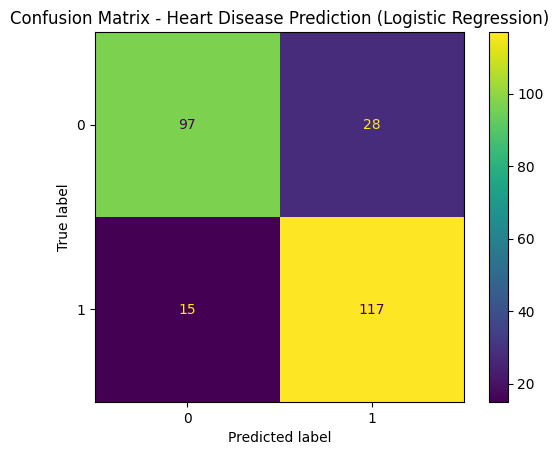

In [26]:

y_pred = model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred, digits=3))


ConfusionMatrixDisplay.from_estimator(model, X_test_scaled, y_test)
plt.title("Confusion Matrix - Heart Disease Prediction (Logistic Regression)")
plt.show()

This cell saves the trained model, the scaler, and a copy of the dataset into an “artifacts” folder for future use or submission

In [27]:

os.makedirs("artifacts", exist_ok=True)
joblib.dump(model, "artifacts/heart_model.joblib")
joblib.dump(scaler, "artifacts/standard_scaler.joblib")
df.to_csv("artifacts/heart_dataset_copy.csv", index=False)

print(" Model, scaler, and dataset saved successfully in ./artifacts/")

 Model, scaler, and dataset saved successfully in ./artifacts/


This visualization shows how age is distributed between patients with and without heart disease using a boxplot.

/tmp/ipython-input-552099329.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='target', y='age', data=df, palette='Set2')


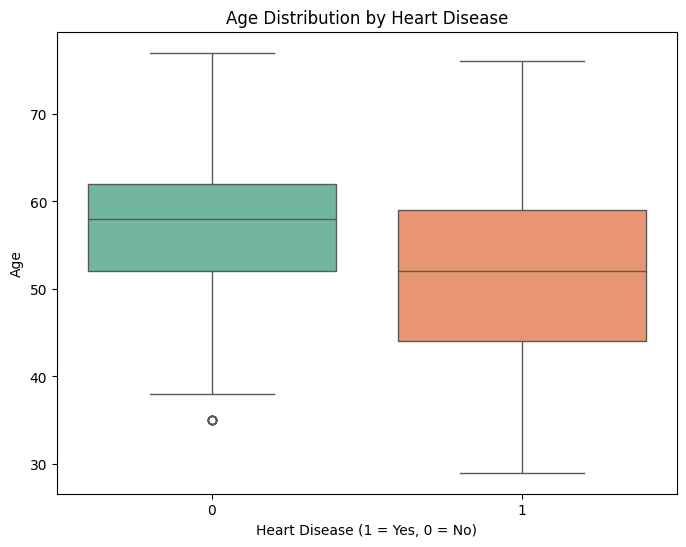

In [28]:
plt.figure(figsize=(8,6))
sns.boxplot(x='target', y='age', data=df, palette='Set2')
plt.title('Age Distribution by Heart Disease')
plt.xlabel('Heart Disease (1 = Yes, 0 = No)')
plt.ylabel('Age')
plt.show()

This heatmap displays the correlation between all features, helping identify which variables are most related to heart disease.

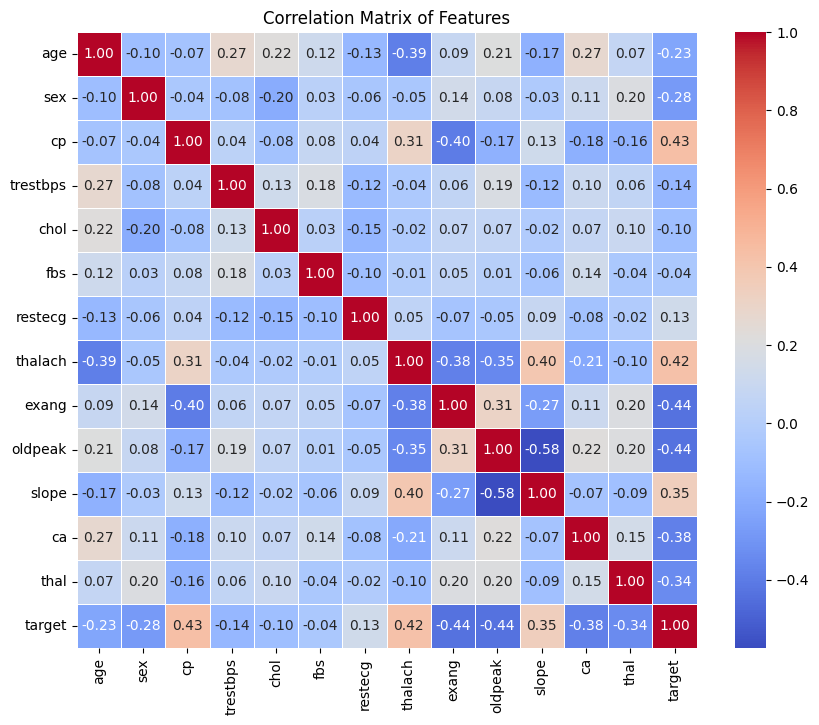

In [29]:

plt.figure(figsize=(10,8))
corr = df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title("Correlation Matrix of Features")
plt.show()

This cell plots histograms for all numerical features to visualize their distributions.

<Figure size 1500x1000 with 0 Axes>

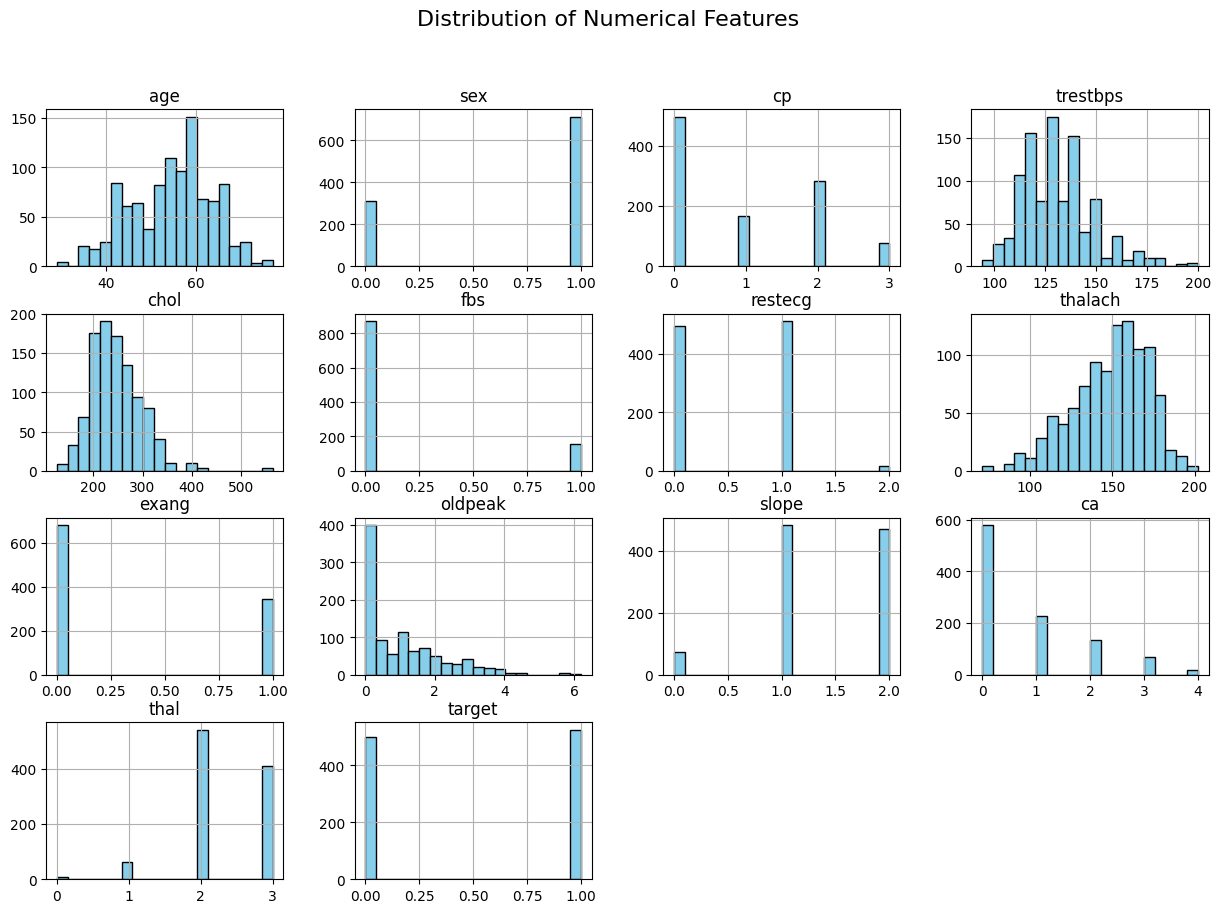

In [30]:

numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

plt.figure(figsize=(15, 10))
df[numeric_cols].hist(bins=20, figsize=(15, 10), color='skyblue', edgecolor='black')
plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.show()